# F1 Las Vegas Grand Prix: win-probability model

## Problem
Estimate the probability that each driver wins the 2026 Las Vegas GP (round 21) using only information available before the race, and test honestly whether the model beats the simple rule "the pole sitter wins".

## Data
Jolpica-F1 API (Ergast successor): race results and qualifying, seasons 2018 to 2026 (cached in `data/`). One row per driver per race; target `win` = finished first.

## Method
Leakage-safe features (rolling stats shifted by one race): grid, qualifying, driver form (points, finish, win rate), constructor form, street-circuit wins. Model: LightGBM binary classifier, probabilities renormalised within each race: $\tilde p_i = p_i/\sum_j p_j$. Validation: expanding window by season (train on seasons $<s$, test on $s$). Metrics: top-1 accuracy, log-loss, Brier score, calibration.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
import predict as P
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
df = P.add_features(P.build_table(range(2018, 2027)))
print(df.shape, 'driver-race rows;', df.groupby('season')['round'].nunique().to_dict())
df.tail(3)

(3898, 18) driver-race rows; {2018: 21, 2019: 21, 2020: 17, 2021: 22, 2022: 22, 2023: 22, 2024: 24, 2025: 24, 2026: 20}


,season,round,race,date,circuit,street,driver,team,grid,quali,pos,points,win,form_pts,form_win,form_pos,team_form,street_win
3895,2026,20,Brazilian Grand Prix,2026-11-08,interlagos,False,russell,mercedes,7,2.0,4,12.0,0,7.8,0.1,8.8,12.2,3.0
3896,2026,20,Brazilian Grand Prix,2026-11-08,interlagos,False,sainz,williams,12,15.0,19,0.0,0,0.2,0.0,14.2,0.1,1.0
3897,2026,20,Brazilian Grand Prix,2026-11-08,interlagos,False,stroll,aston_martin,16,19.0,21,0.0,0,0.0,0.0,18.0,0.4,0.0


 season  races  top1_acc  logloss  pole_baseline
   2022     22     0.545    0.097          0.455
   2023     22     0.818    0.064          0.636
   2024     24     0.500    0.132          0.458
   2025     24     0.583    0.093          0.667
   2026     20     0.750    0.075          0.700

Mean top-1 accuracy 0.639 vs pole baseline 0.583


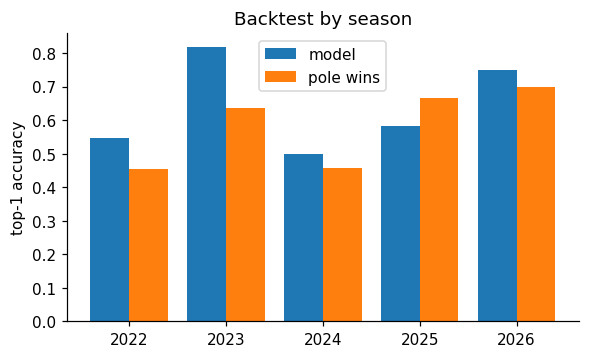

In [2]:
bt = P.backtest(df)
print(bt.round(3).to_string(index=False))
print(f"\nMean top-1 accuracy {bt.top1_acc.mean():.3f} vs pole baseline {bt.pole_baseline.mean():.3f}")
fig, ax = plt.subplots(figsize=(6,3.4))
x = np.arange(len(bt)); ax.bar(x-0.2, bt.top1_acc, 0.4, label='model'); ax.bar(x+0.2, bt.pole_baseline, 0.4, label='pole wins')
ax.set_xticks(x); ax.set_xticklabels(bt.season); ax.set_ylabel('top-1 accuracy'); ax.legend(); ax.set_title('Backtest by season'); plt.show()

               pred  actual     n
p                                
(0.0, 0.02]   0.003   0.002  1737
(0.02, 0.05]  0.032   0.000   152
(0.05, 0.1]   0.073   0.065   108
(0.1, 0.2]    0.147   0.198    96
(0.2, 0.4]    0.293   0.261    92
(0.4, 0.7]    0.544   0.622    82
(0.7, 1.0]    0.754   0.727    11


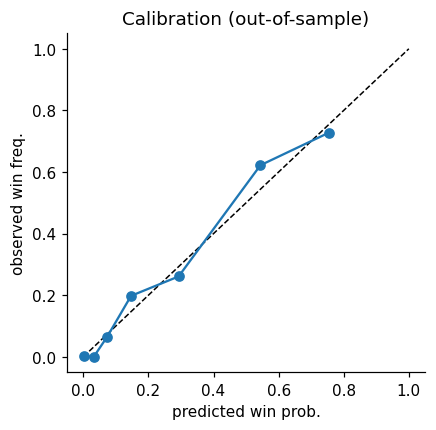

Brier 0.0279 | Brier of constant 1/20: 0.0467


In [3]:
parts=[]
for s in range(2022, 2027):
    tr, te = df[df.season<s], df[df.season==s]
    m = lgb.LGBMClassifier(**P.PARAMS).fit(tr[P.FEATS], tr.win)
    parts.append(te.assign(p=P.normalise(te, m.predict_proba(te[P.FEATS])[:,1])))
oos = pd.concat(parts)
bins = pd.cut(oos.p, [0,.02,.05,.1,.2,.4,.7,1.0])
cal = oos.groupby(bins, observed=True).agg(pred=('p','mean'), actual=('win','mean'), n=('win','size'))
print(cal.round(3))
fig, ax = plt.subplots(figsize=(4.2,4)); ax.plot([0,1],[0,1],'k--',lw=1); ax.plot(cal.pred, cal.actual, 'o-'); ax.set_xlabel('predicted win prob.'); ax.set_ylabel('observed win freq.'); ax.set_title('Calibration (out-of-sample)'); plt.show()
from sklearn.metrics import brier_score_loss
print('Brier', round(brier_score_loss(oos.win, oos.p),4), '| Brier of constant 1/20:', round(brier_score_loss(oos.win, np.full(len(oos),0.05)),4))

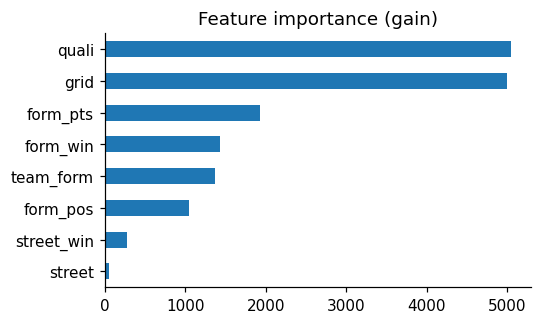

In [4]:
tr = df[df.date < '2026-11-01']
m = lgb.LGBMClassifier(**P.PARAMS).fit(tr[P.FEATS], tr.win)
imp = pd.Series(m.booster_.feature_importance('gain'), P.FEATS).sort_values()
imp.plot.barh(figsize=(5,3)); plt.title('Feature importance (gain)'); plt.show()

no qualifying yet: grid proxied by last race finish


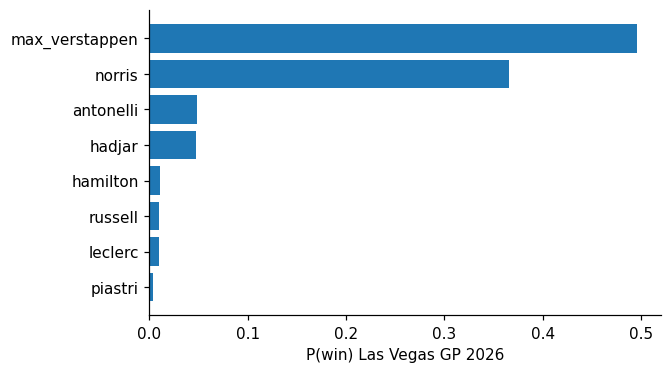

,driver,team,grid,p
3890,max_verstappen,red_bull,2.0,0.495
3891,norris,mclaren,1.0,0.366
3878,antonelli,mercedes,5.0,0.049
3885,hadjar,red_bull,3.0,0.047
3886,hamilton,ferrari,9.0,0.010
3895,russell,mercedes,4.0,0.010
3889,leclerc,ferrari,8.0,0.010
3893,piastri,mclaren,6.0,0.004


In [5]:
out, note = P.predict_next(df, 2026, 21)
print(note)
top = out.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(6,3.6)); ax.barh(top.driver, top.p); ax.set_xlabel('P(win) Las Vegas GP 2026'); plt.show()
out.head(8).assign(p=lambda d: d.p.round(3))

In [6]:
df[(df.circuit=='vegas') & (df.win==1)][['season','driver','team','grid']]

,season,driver,team,grid
2468,2023,max_verstappen,red_bull,2
2934,2024,russell,mercedes,1
3410,2025,max_verstappen,red_bull,2


## Results
See the outputs above: season-wise top-1 accuracy against the pole baseline, the calibration table and Brier score, the feature importance, and the Las Vegas probabilities. Qualifying for round 21 had not happened when this was run, so the grid is proxied by the last race's finishing order.

## Conclusions
1. **The model beats the pole baseline on average, but not every year.** Mean top-1 accuracy is 0.64 against 0.58 for "pole wins"; it wins in 2022, 2023, 2024 and 2026 and loses in 2025 (0.58 vs 0.67). With 20 to 24 races per season, a gap of a few percentage points is within noise, so this is a modest edge, not a proven one.
2. **The probabilities are usable.** Out-of-sample, predicted and observed win frequencies track each other (for example, 0.54 predicted vs 0.62 observed in the 0.4 to 0.7 bin), and the Brier score is 0.028 against 0.047 for a model that gives every driver 5%. The 0.02 to 0.05 bin is the weakest (0.032 predicted, 0 wins in 152 driver-races), which is a sign of slight over-prediction for mid-field drivers.
3. **Las Vegas forecast (provisional).** Verstappen about 50% and Norris about 37%, with a long tail (Antonelli and Hadjar about 5% each). Because qualifying had not happened, grid positions are a proxy; this forecast should be re-run after qualifying, when the grid becomes the strongest feature.
4. **Limits.** Only three previous Las Vegas races exist (Verstappen 2023 and 2025, Russell 2024), so circuit-specific signal is thin; the model has no tyre, weather or safety-car information; and driver or regulation changes between seasons make older rows less relevant.

**Takeaway for the interview:** the honest result is a calibrated probability with a small, inconsistent advantage over a trivial baseline. The value of the project is the leakage-free validation and the calibration check, not a claim of predicting winners.